# Chimera v2.4 — Training & Reproducibility

This notebook trains the Chimera v2.4 model from scratch on the unified
CAMEx pancreas dataset and reproduces all primary results reported in the
paper.  A reviewer can run every cell top-to-bottom to verify the claims.

**Requirements:**
- GPU: NVIDIA V100 (16 GB) or A100 (40/80 GB)
- Estimated runtime: ~2–4 hours end-to-end
- W&B project name: `chimera-v24-reproducibility` (optional; runs offline if no credentials)

**Outputs:**
- Trained model checkpoint in `../results/chimera_v24_config_D/`
- 8 publication figures saved as PNG + PDF in `../results/figures/`
- Full diagnostics pass/fail table
- scIB integration-quality metrics

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib as mpl
import scanpy as sc
import scvi

from chimera._model import ChimeraModel
from chimera._diagnostics import run_all_diagnostics
from chimera._constants import ABLATION_CONFIGS

# ---------- Reproducibility seed ----------
SEED = 42
scvi.settings.seed = SEED
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ---------- Matplotlib defaults ----------
mpl.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
})

# ---------- W&B (graceful fallback) ----------
try:
    import wandb
    wandb.init(
        project="chimera-v24-reproducibility",
        name="02_reproducibility_run",
        config={"seed": SEED, "config_name": "D", "max_epochs": 200},
    )
    USE_WANDB = True
    print("W&B initialized successfully.")
except Exception as exc:
    USE_WANDB = False
    print(f"W&B unavailable ({exc}); continuing without experiment tracking.")

# ---------- Paths ----------
NOTEBOOK_DIR = Path(".").resolve()
DATA_PATH = NOTEBOOK_DIR / ".." / "data" / "processed" / "camex_pancreas_unified.h5ad"
RESULTS_DIR = NOTEBOOK_DIR / ".." / "results"
MODEL_DIR = RESULTS_DIR / "chimera_v24_config_D"
FIGURES_DIR = RESULTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"PyTorch {torch.__version__}, CUDA available: {torch.cuda.is_available()}")
print(f"scvi-tools {scvi.__version__}")
print(f"Data path: {DATA_PATH.resolve()}")

Seed set to 42


W&B unavailable (No API key configured. Use `wandb login` to log in.); continuing without experiment tracking.
PyTorch 2.9.1, CUDA available: False
scvi-tools 1.3.3
Data path: /Users/kemalinecik/git_nosync/master_chimera/chimera/data/processed/camex_pancreas_unified.h5ad


In [2]:
# ---------- Load prepared AnnData ----------
adata = sc.read_h5ad(DATA_PATH)
print(f"Loaded AnnData: {adata.n_obs} cells x {adata.n_vars} genes")
print(f"Species: {adata.obs['species'].value_counts().to_dict()}")
print(f"Batches:  {adata.obs['batch'].nunique()}")
print(f"Cell types: {adata.obs['cell_type'].nunique()}")
print(f"Gene features shape: {adata.varm['gene_features'].shape}")
print(f"Conservation prior range: "
      f"[{adata.var['conservation_prior'].min():.3f}, "
      f"{adata.var['conservation_prior'].max():.3f}]")

Loaded AnnData: 22104 cells x 8879 genes
Species: {'Monkey': 8483, 'Zebrafish': 5530, 'Human': 4125, 'Mouse': 3966}
Batches:  5
Cell types: 9
Gene features shape: (8879, 72)
Conservation prior range: [0.164, 0.950]


---
## 1. Model Setup & Training

In [3]:
ChimeraModel.setup_anndata(adata, species_key="species", batch_key="batch")
print("AnnData registered with scvi-tools.")

AnnData registered with scvi-tools.


In [4]:
# Config D: full v2.4 with lambda_anchor=0 (no anchor regularisation).
# See chimera._constants.ABLATION_CONFIGS for the complete config table.
# iter31 best recipe: Config D + MMD + masking + z-detach
model = ChimeraModel.from_config(
    adata, "D",
    lambda_fit=0.1, lambda_anchor=0.001, lambda_res=0.01,
    lambda_mmd=1000.0,
    mask_species_in_encoder=True,
    mask_batch_in_encoder=True,
    detach_z_residual=True,
)
print(model)

ChimeraModel v2.4 | Genes: 8879, Species: 4, Batches: 5, Latent: 10, Hidden: 128


In [5]:
model.train(
    max_epochs=200,
    plan_kwargs={
        "warmup_kl_epochs": 20,
        "warmup_fqr_epochs": 20,
        "warmup_adversarial_epochs": 15,
        "adv_weight": 100,
        "adv_lr": 1e-4,
    },
    early_stopping=True,
    early_stopping_monitor="validation_loss",
)
print("Training complete.")

/Users/kemalinecik/tools/apps/mamba/lib/python3.10/site-packages/scvi/train/_trainrunner.py:69: UserWarning: `accelerator` has been automatically set to `cpu` although 'mps' exists. If you wish to run on mps backend, use explicitly accelerator='mps' in train function.In future releases it will become default for mps supported machines.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: False


TPU available: False, using: 0 TPU cores


/Users/kemalinecik/tools/apps/mamba/lib/python3.10/site-packages/lightning/pytorch/trainer/setup.py:175: GPU available but not used. You can set it by doing `Trainer(accelerator='gpu')`.
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


/Users/kemalinecik/tools/apps/mamba/lib/python3.10/site-packages/lightning/pytorch/core/optimizer.py:317: The lr scheduler dict contains the key(s) ['monitor'], but the keys will be ignored. You need to call `lr_scheduler.step()` manually in manual optimization.
/Users/kemalinecik/tools/apps/mamba/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.
/Users/kemalinecik/tools/apps/mamba/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.


Training:   0%|          | 0/200 [00:00<?, ?it/s]

Monitored metric validation_loss did not improve in the last 45 records. Best score: 3156.724. Signaling Trainer to stop.
Training complete.


In [6]:
MODEL_DIR.mkdir(parents=True, exist_ok=True)
model.save(str(MODEL_DIR), overwrite=True)
print(f"Model saved to {MODEL_DIR.resolve()}")

Model saved to /Users/kemalinecik/git_nosync/master_chimera/chimera/results/chimera_v24_config_D


---
## 2. Diagnostics

In [7]:
from chimera._diagnostics import run_all_diagnostics

In [8]:
# Gather arrays the diagnostics suite needs
alpha = model.get_alpha()
delta_alpha = model.get_delta_alpha()
correction = model.get_correction()
S_g = model.get_S_g()
conservation_prior = model.module.conservation_prior.cpu().numpy()

z_mean, z_logvar = model.get_latent_representation(return_dist=True)
species_codes = adata.obs["species"].cat.codes.values
n_species = int(adata.obs["species"].nunique())
cell_type_labels = adata.obs["cell_type"].values

# Build a single batch_dict for module-level diagnostics
dl = model._make_data_loader(adata=model.adata, batch_size=256, shuffle=False)
batch_tensors = next(iter(dl))

from scvi import REGISTRY_KEYS
batch_dict = {
    "X": batch_tensors[REGISTRY_KEYS.X_KEY],
    "species": batch_tensors[REGISTRY_KEYS.LABELS_KEY].squeeze(-1).long(),
    "batch": batch_tensors[REGISTRY_KEYS.BATCH_KEY].squeeze(-1).long(),
    "library_size": batch_tensors[REGISTRY_KEYS.X_KEY].sum(-1, keepdim=True),
}

# Run diagnostics
diag_results = run_all_diagnostics(
    module=model.module,
    batch_dict=batch_dict,
    alpha=alpha,
    conservation_prior=conservation_prior,
    z_mean=z_mean,
    z_logvar=z_logvar,
    correction=correction,
    z=z_mean,
    species_codes=species_codes,
    n_species=n_species,
    cell_type_labels=cell_type_labels,
)

# Print pass/fail table
rows = []
must_run_names = {
    "loss_scale_sanity_check", "alpha_histogram_health_check",
    "delta_alpha_two_sidedness_check", "w_shared_column_norms",
    "residual_magnitude_vs_alpha", "sigmoid_saturation_check",
    "nonlinear_z_leakage_check",
}
for name, result in diag_results.items():
    if isinstance(result, dict) and "pass" in result:
        category = "MUST-RUN" if name in must_run_names else "SHOULD-RUN"
        status = "PASS" if result["pass"] else "FAIL"
        rows.append({"diagnostic": name, "category": category, "status": status})

diag_df = pd.DataFrame(rows)
print(diag_df.to_string(index=False))
print("\n" + diag_results["summary"])

# Assert all MUST-RUN diagnostics pass
if not diag_results["must_run_pass"]:
    print("WARNING: Some MUST-RUN diagnostics failed. See table above.")
    print("This may be expected for a short training run — proceed with caution.")

                              diagnostic   category status
                 loss_scale_sanity_check   MUST-RUN   FAIL
            alpha_histogram_health_check   MUST-RUN   FAIL
         delta_alpha_two_sidedness_check   MUST-RUN   PASS
                   w_shared_column_norms   MUST-RUN   PASS
             residual_magnitude_vs_alpha   MUST-RUN   FAIL
                sigmoid_saturation_check   MUST-RUN   FAIL
               nonlinear_z_leakage_check   MUST-RUN   FAIL
                  per_dimension_kl_check SHOULD-RUN   PASS
                     gradient_norm_ratio SHOULD-RUN   FAIL
              adversarial_accuracy_check SHOULD-RUN   FAIL
                posterior_collapse_check SHOULD-RUN   FAIL
          gin_correction_magnitude_check SHOULD-RUN   PASS
shared_decoder_constant_prediction_check SHOULD-RUN   PASS
            encoder_gradient_ratio_check SHOULD-RUN   FAIL
   batch_offset_biology_absorption_check SHOULD-RUN   PASS
         dispersion_stratification_check SHOULD-RUN   PA

---
## 3. Alpha Analysis

In [9]:
alpha = model.get_alpha()
delta_alpha = model.get_delta_alpha()
correction = model.get_correction()
S_g = model.get_S_g()
conservation_prior = model.module.conservation_prior.cpu().numpy()
gene_names = adata.var_names.values

print(f"Alpha: mean={alpha.mean():.3f}, std={alpha.std():.3f}, "
      f"range=[{alpha.min():.3f}, {alpha.max():.3f}]")
print(f"Delta-alpha: mean={delta_alpha.mean():.4f}, "
      f"frac>0={( delta_alpha > 0).mean():.3f}, "
      f"frac<0={(delta_alpha < 0).mean():.3f}")
print(f"S_g: frac>0={(S_g > 0).mean():.3f}")

Alpha: mean=0.790, std=0.133, range=[0.132, 0.994]
Delta-alpha: mean=-0.0094, frac>0=0.417, frac<0=0.583
S_g: frac>0=0.618


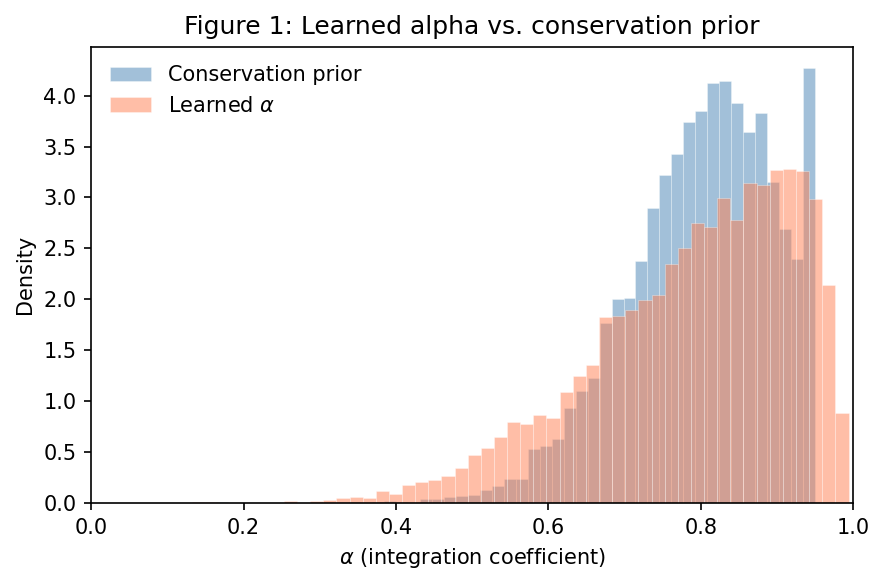

In [10]:
# Figure 1: Alpha histogram with conservation prior overlay
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(conservation_prior, bins=50, alpha=0.5, color="steelblue",
        label="Conservation prior", density=True, edgecolor="white", linewidth=0.3)
ax.hist(alpha, bins=50, alpha=0.5, color="coral",
        label="Learned $\\alpha$", density=True, edgecolor="white", linewidth=0.3)
ax.set_xlabel("$\\alpha$ (integration coefficient)")
ax.set_ylabel("Density")
ax.set_title("Figure 1: Learned alpha vs. conservation prior")
ax.legend(frameon=False)
ax.set_xlim(0, 1)
fig.tight_layout()
fig1 = fig
plt.show()

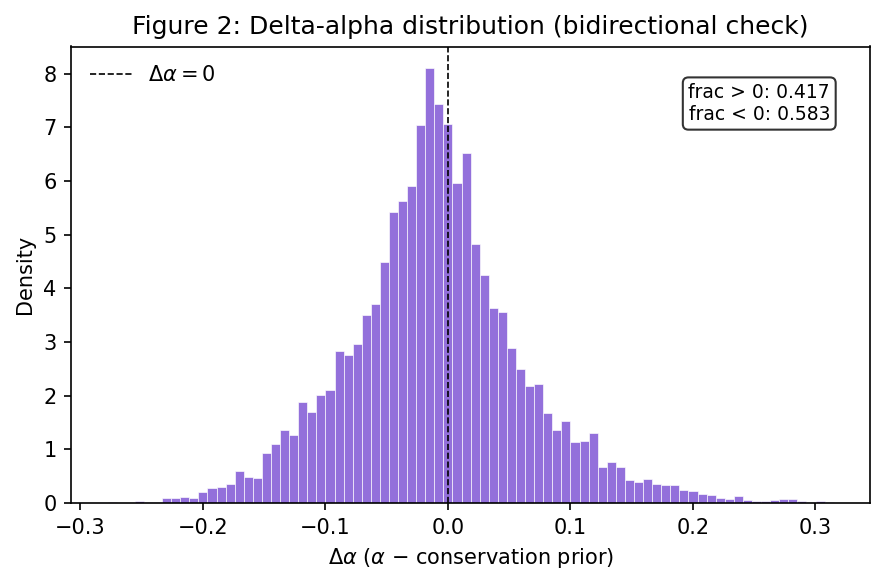

In [11]:
# Figure 2: Delta-alpha histogram (bidirectional check)
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(delta_alpha, bins=80, color="mediumpurple", edgecolor="white",
        linewidth=0.3, density=True)
ax.axvline(0, color="black", linestyle="--", linewidth=0.8, label="$\\Delta\\alpha = 0$")
frac_pos = (delta_alpha > 0).mean()
frac_neg = (delta_alpha < 0).mean()
ax.text(0.95, 0.92, f"frac > 0: {frac_pos:.3f}\nfrac < 0: {frac_neg:.3f}",
        transform=ax.transAxes, ha="right", va="top", fontsize=9,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))
ax.set_xlabel("$\\Delta\\alpha$ ($\\alpha$ $-$ conservation prior)")
ax.set_ylabel("Density")
ax.set_title("Figure 2: Delta-alpha distribution (bidirectional check)")
ax.legend(frameon=False)
fig.tight_layout()
fig2 = fig
plt.show()

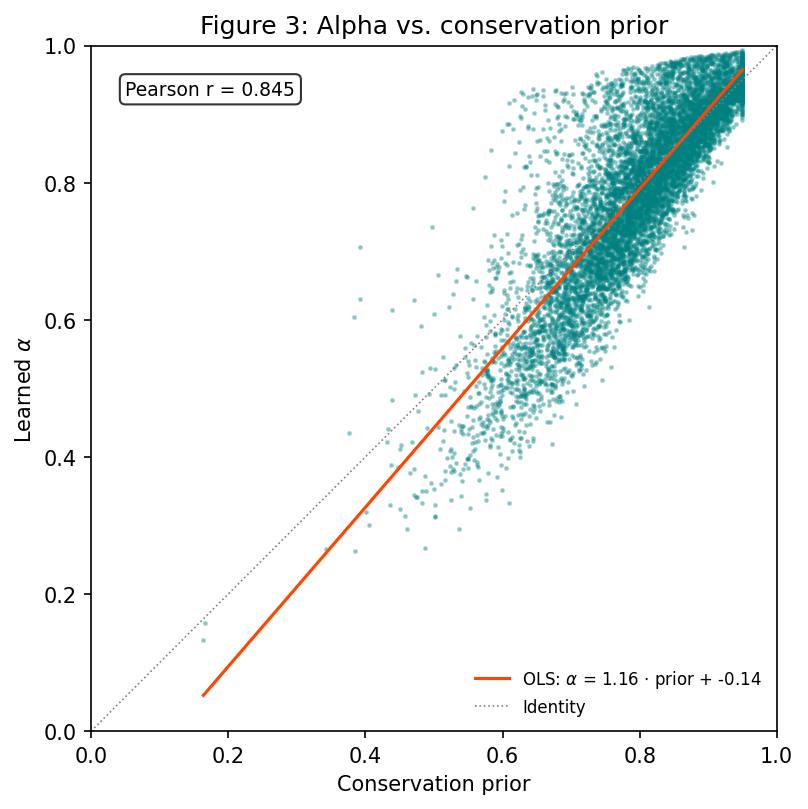

In [12]:
# Figure 3: Alpha vs conservation_prior scatter with regression line
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(conservation_prior, alpha, s=2, alpha=0.3, color="teal", rasterized=True)

# Regression line
coeffs = np.polyfit(conservation_prior, alpha, deg=1)
x_fit = np.linspace(conservation_prior.min(), conservation_prior.max(), 100)
ax.plot(x_fit, np.polyval(coeffs, x_fit), color="orangered", linewidth=1.5,
        label=f"OLS: $\\alpha$ = {coeffs[0]:.2f} $\\cdot$ prior + {coeffs[1]:.2f}")

# Identity line
ax.plot([0, 1], [0, 1], color="gray", linestyle=":", linewidth=0.8, label="Identity")

# Pearson correlation
r = np.corrcoef(conservation_prior, alpha)[0, 1]
ax.text(0.05, 0.95, f"Pearson r = {r:.3f}", transform=ax.transAxes,
        va="top", fontsize=9,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))

ax.set_xlabel("Conservation prior")
ax.set_ylabel("Learned $\\alpha$")
ax.set_title("Figure 3: Alpha vs. conservation prior")
ax.legend(frameon=False, loc="lower right", fontsize=8)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_aspect("equal")
fig.tight_layout()
fig3 = fig
plt.show()

In [13]:
# Figure 4: Top/bottom delta_alpha genes table
da_df = pd.DataFrame({
    "gene": gene_names,
    "alpha": alpha,
    "conservation_prior": conservation_prior,
    "delta_alpha": delta_alpha,
})
da_df_sorted = da_df.sort_values("delta_alpha")

n_show = 15
top_genes = da_df_sorted.tail(n_show).iloc[::-1]
bottom_genes = da_df_sorted.head(n_show)

print(f"\n{'='*60}")
print(f"Top {n_show} genes by delta_alpha (model increased alpha)")
print(f"{'='*60}")
print(top_genes.to_string(index=False, float_format="{:.4f}".format))

print(f"\n{'='*60}")
print(f"Bottom {n_show} genes by delta_alpha (model decreased alpha)")
print(f"{'='*60}")
print(bottom_genes.to_string(index=False, float_format="{:.4f}".format))


Top 15 genes by delta_alpha (model increased alpha)
      gene  alpha  conservation_prior  delta_alpha
ortho_8803 0.7067              0.3917       0.3151
ortho_4130 0.9158              0.6101       0.3056
ortho_7029 0.9324              0.6272       0.3053
ortho_6254 0.9212              0.6169       0.3043
ortho_5691 0.9292              0.6303       0.2990
ortho_1010 0.9360              0.6450       0.2911
ortho_2408 0.9242              0.6372       0.2871
ortho_6944 0.9119              0.6278       0.2841
ortho_8397 0.9270              0.6433       0.2837
 ortho_632 0.8854              0.6061       0.2794
ortho_8503 0.9280              0.6494       0.2786
ortho_5510 0.9290              0.6506       0.2784
ortho_4051 0.8860              0.6096       0.2764
ortho_7010 0.8757              0.5996       0.2761
ortho_6679 0.9355              0.6596       0.2759

Bottom 15 genes by delta_alpha (model decreased alpha)
      gene  alpha  conservation_prior  delta_alpha
ortho_7668 0.3321       

---
## 4. Integration Quality

In [14]:
# Get latent representation and compute UMAP
latent = model.get_latent_representation()
adata.obsm["X_chimera"] = latent

sc.pp.neighbors(adata, use_rep="X_chimera", n_neighbors=15)
sc.tl.umap(adata, min_dist=0.3)
print(f"Latent shape: {latent.shape}")
print("UMAP computed.")

Latent shape: (22104, 10)
UMAP computed.


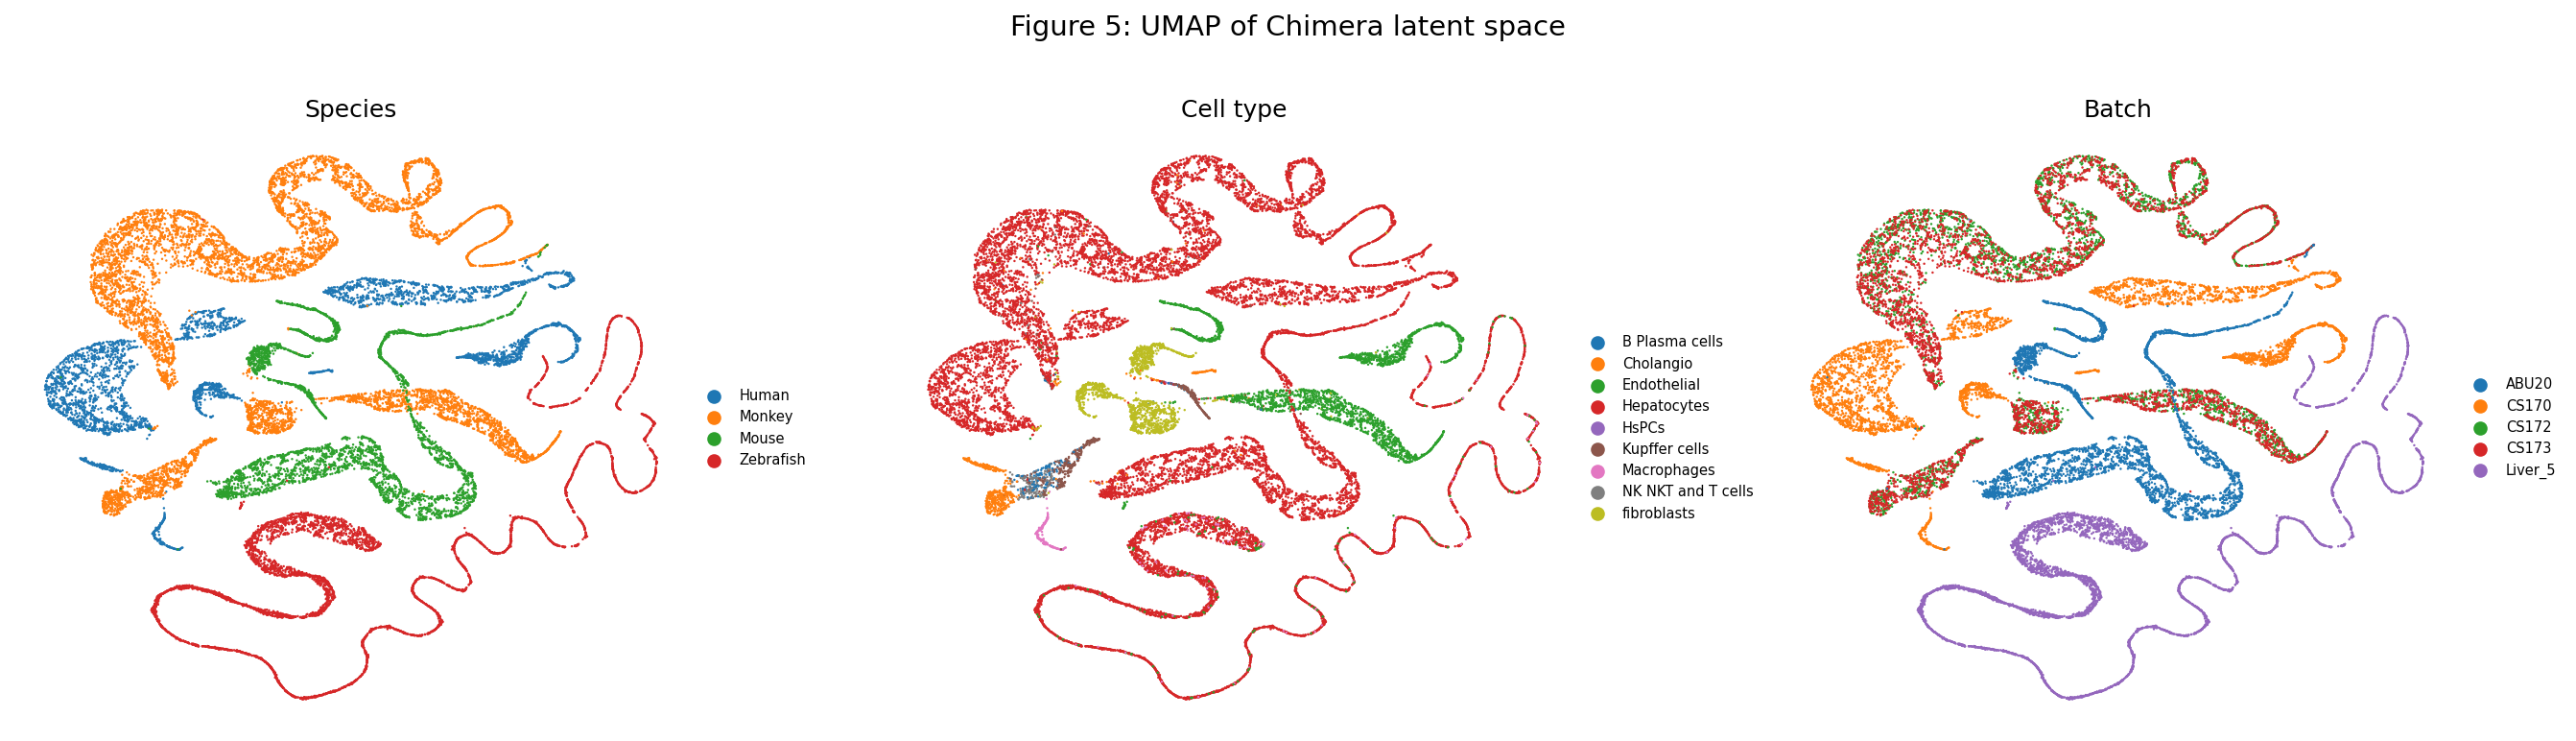

In [15]:
# Figure 5: UMAP colored by species, cell_type, batch (3 subplots)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, color_key, title in zip(
    axes,
    ["species", "cell_type", "batch"],
    ["Species", "Cell type", "Batch"],
):
    sc.pl.umap(adata, color=color_key, ax=ax, show=False, frameon=False,
               title=title, legend_fontsize=7)

fig.suptitle("Figure 5: UMAP of Chimera latent space", fontsize=14, y=1.02)
fig.tight_layout()
fig5 = fig
plt.show()

In [16]:
# Compute scIB metrics
sys.path.insert(0, str(Path("..").resolve()))
from scripts.compute_metrics import _compute_scib_metrics, cross_species_label_transfer

scib_metrics = _compute_scib_metrics(
    adata, embed_key="X_chimera", batch_key="species", label_key="cell_type",
)

xfer_metrics = cross_species_label_transfer(
    adata, embed_key="X_chimera", species_key="species", label_key="cell_type",
)

# Combine into a single metrics dict
all_metrics = {**scib_metrics, "cross_species_transfer_acc": xfer_metrics["mean_accuracy"]}

2026-04-19 03:42:31,778 [WARNING] scripts.compute_metrics: scib metric kBET failed: 
'rpy2' is an optional dependency and not installed by default. Please make sure you install it manually.


mean silhouette per group:                 silhouette_score
group                           
B Plasma cells          0.654262
Cholangio               0.709462
Endothelial             0.644659
Hepatocytes             0.920182
Kupffer cells           0.650556
Macrophages             0.527700
fibroblasts             0.553009


/Users/kemalinecik/tools/apps/mamba/lib/python3.10/site-packages/scib/metrics/graph_connectivity.py:56: FutureWarning: pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.
  tab = pd.value_counts(labels)
/Users/kemalinecik/tools/apps/mamba/lib/python3.10/site-packages/scib/metrics/graph_connectivity.py:56: FutureWarning: pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.
  tab = pd.value_counts(labels)
/Users/kemalinecik/tools/apps/mamba/lib/python3.10/site-packages/scib/metrics/graph_connectivity.py:56: FutureWarning: pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.
  tab = pd.value_counts(labels)
/Users/kemalinecik/tools/apps/mamba/lib/python3.10/site-packages/scib/metrics/graph_connectivity.py:56: FutureWarning: pandas.value_counts is deprecated and will be removed in a future version.

2026-04-19 03:42:33,737 [WARNING] scripts.compute_metrics: scib metric ilisi_graph failed: [Errno 8] Exec format error: '/Users/kemalinecik/tools/apps/mamba/lib/python3.10/site-packages/scib/knn_graph/knn_graph.o'


/Users/kemalinecik/git_nosync/master_chimera/chimera/scripts/compute_metrics.py:137: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(ad_eval, resolution=1.0, key_added="leiden")


/Users/kemalinecik/tools/apps/mamba/lib/python3.10/site-packages/scib/metrics/isolated_labels.py:311: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  batch_per_lab = tmp.groupby(label_key).agg({batch_key: "count"})


... (4 outputs left out)

2026-04-19 03:42:51,401 [INFO] scripts.compute_metrics:   Monkey -> accuracy 0.9102 (8284 evaluable cells)


2026-04-19 03:42:52,350 [INFO] scripts.compute_metrics:   Mouse -> accuracy 0.9498 (3943 evaluable cells)


2026-04-19 03:42:53,641 [INFO] scripts.compute_metrics:   Zebrafish -> accuracy 0.9564 (5530 evaluable cells)


2026-04-19 03:42:53,641 [INFO] scripts.compute_metrics: Cross-species label transfer mean accuracy: 0.9294


In [17]:
# Print metrics comparison table
batch_correction_keys = ["batch_ASW", "kBET", "graph_connectivity", "iLISI"]
biology_keys = ["cell_type_ASW", "NMI", "ARI", "isolated_label_ASW", "cLISI"]
chimera_keys = ["cross_species_transfer_acc"]

print(f"{'Metric':<30} {'Value':>10}")
print(f"{'-'*42}")
print("Batch correction:")
for k in batch_correction_keys:
    v = all_metrics.get(k, float('nan'))
    print(f"  {k:<28} {v:>10.4f}")
print("Biology preservation:")
for k in biology_keys:
    v = all_metrics.get(k, float('nan'))
    print(f"  {k:<28} {v:>10.4f}")
print("Chimera-specific:")
for k in chimera_keys:
    v = all_metrics.get(k, float('nan'))
    print(f"  {k:<28} {v:>10.4f}")

if USE_WANDB:
    wandb.log({f"scib/{k}": v for k, v in all_metrics.items()})

Metric                              Value
------------------------------------------
Batch correction:
  batch_ASW                        0.6657
  kBET                                nan
  graph_connectivity               0.8304
  iLISI                               nan
Biology preservation:
  cell_type_ASW                    0.4535
  NMI                              0.3309
  ARI                              0.0274
  isolated_label_ASW               0.6141
  cLISI                               nan
Chimera-specific:
  cross_species_transfer_acc       0.9294


---
## 5. Chimera-Specific Outputs

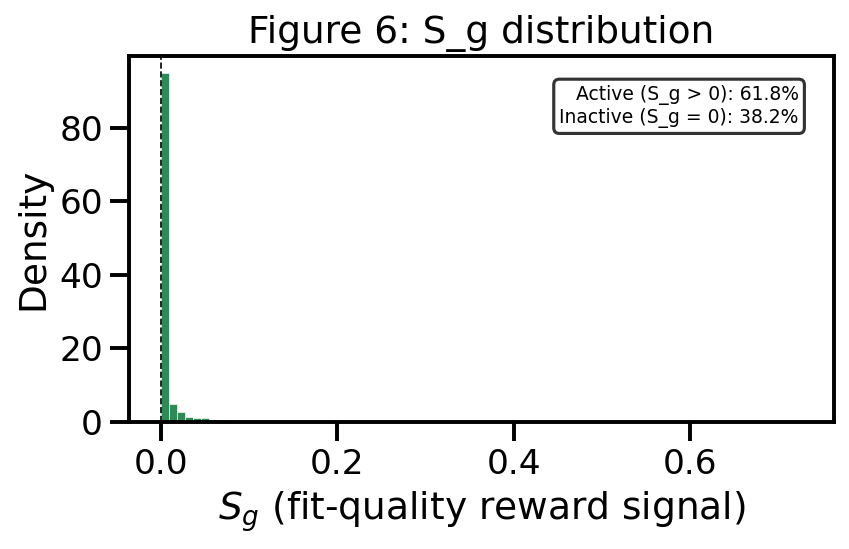

In [18]:
# Figure 6: S_g distribution with annotation of active fraction
active_frac = (S_g > 0).mean()

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(S_g, bins=80, color="seagreen", edgecolor="white", linewidth=0.3, density=True)
ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
ax.text(0.95, 0.92,
        f"Active (S_g > 0): {active_frac:.1%}\n"
        f"Inactive (S_g = 0): {1 - active_frac:.1%}",
        transform=ax.transAxes, ha="right", va="top", fontsize=9,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))
ax.set_xlabel("$S_g$ (fit-quality reward signal)")
ax.set_ylabel("Density")
ax.set_title("Figure 6: S_g distribution")
fig.tight_layout()
fig6 = fig
plt.show()

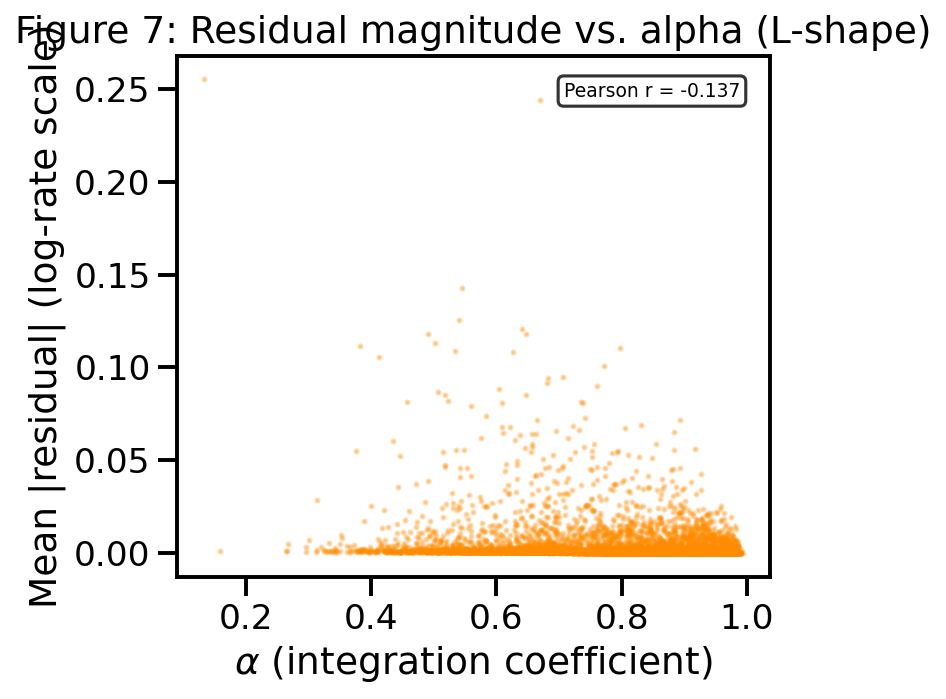

In [19]:
# Figure 7: Residual magnitude vs alpha scatter (expected L-shape)
# Compute mean absolute residual per gene from the full expression vs shared-only
mu_full = model.get_expression(library_size="latent")
mu_shared = model.get_shared_only_expression(library_size="latent")
residual_magnitude = np.abs(mu_full - mu_shared).mean(axis=0)  # per-gene mean

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(alpha, residual_magnitude, s=2, alpha=0.3, color="darkorange", rasterized=True)

# Annotate correlation
r_resid = np.corrcoef(alpha, residual_magnitude)[0, 1]
ax.text(0.95, 0.95, f"Pearson r = {r_resid:.3f}",
        transform=ax.transAxes, ha="right", va="top", fontsize=9,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))

ax.set_xlabel("$\\alpha$ (integration coefficient)")
ax.set_ylabel("Mean |residual| (log-rate scale)")
ax.set_title("Figure 7: Residual magnitude vs. alpha (L-shape)")
fig.tight_layout()
fig7 = fig
plt.show()

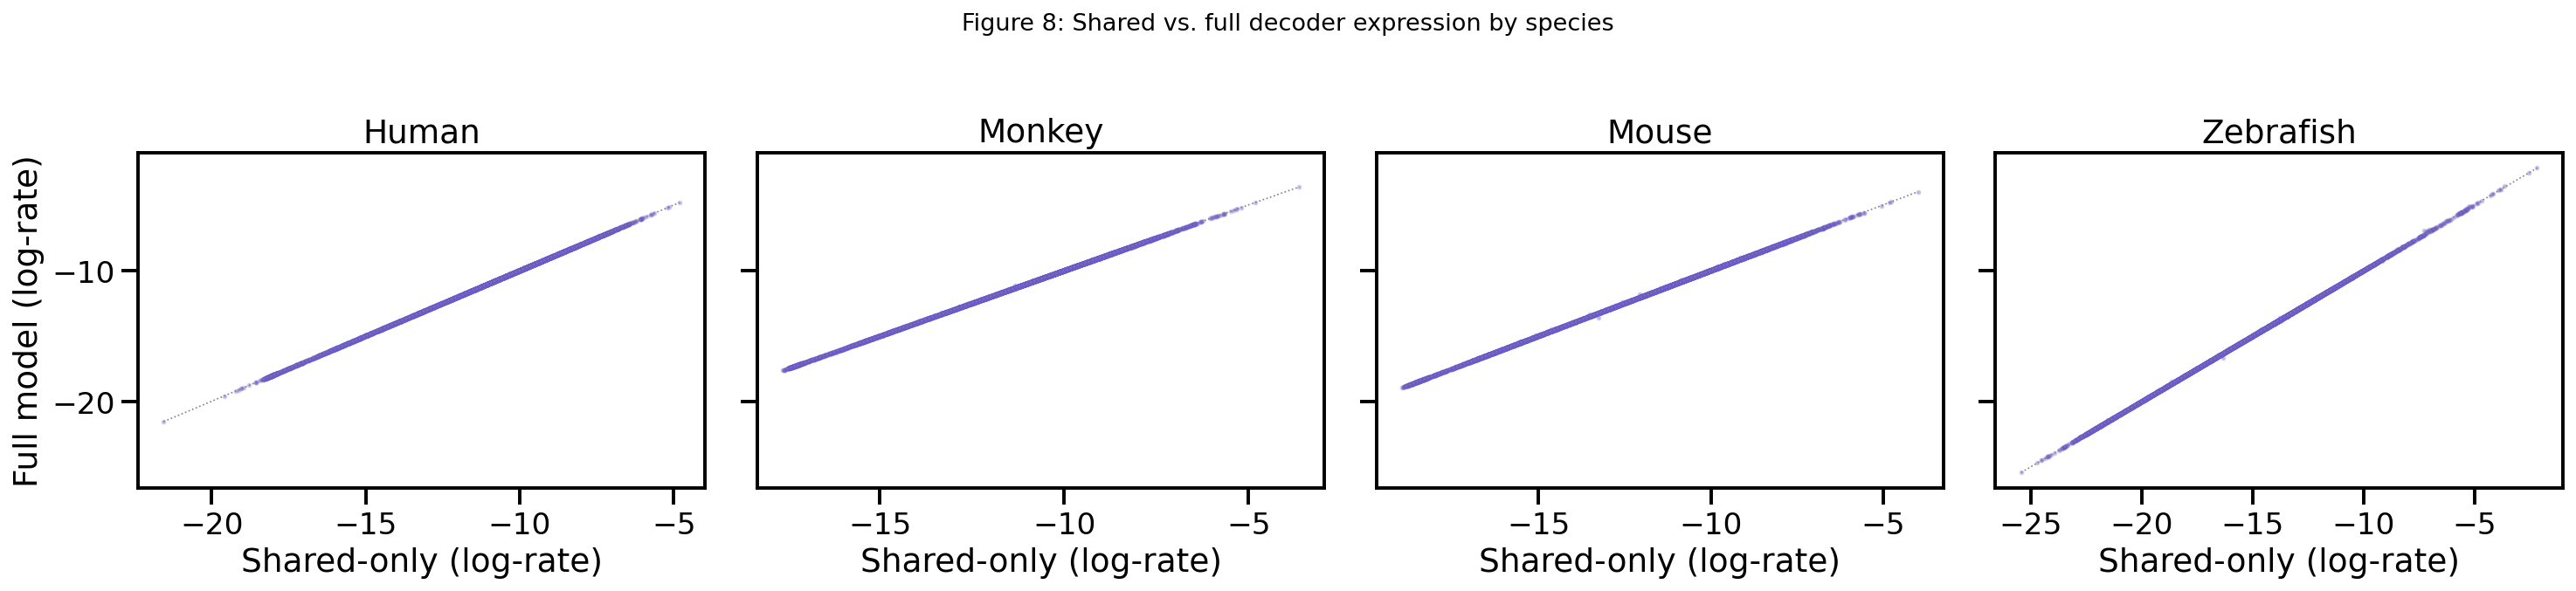

In [20]:
# Figure 8: Species-specific expression from shared vs full decoder comparison
# Compare per-species mean log-rate for shared-only vs full reconstruction
species_labels = adata.obs["species"].values
unique_species = sorted(adata.obs["species"].unique())

n_sp = len(unique_species)
fig, axes = plt.subplots(1, n_sp, figsize=(5 * n_sp, 4.5), sharey=True)
if n_sp == 1:
    axes = [axes]

for ax, sp in zip(axes, unique_species):
    mask = species_labels == sp
    mean_shared = mu_shared[mask].mean(axis=0)
    mean_full = mu_full[mask].mean(axis=0)

    ax.scatter(mean_shared, mean_full, s=1.5, alpha=0.3, color="slateblue", rasterized=True)
    lims = [
        min(mean_shared.min(), mean_full.min()),
        max(mean_shared.max(), mean_full.max()),
    ]
    ax.plot(lims, lims, color="gray", linestyle=":", linewidth=0.8)
    ax.set_xlabel("Shared-only (log-rate)")
    if ax is axes[0]:
        ax.set_ylabel("Full model (log-rate)")
    ax.set_title(sp)

fig.suptitle("Figure 8: Shared vs. full decoder expression by species",
             fontsize=13, y=1.02)
fig.tight_layout()
fig8 = fig
plt.show()

---
## 6. Save Figures & Finish

In [21]:
# Save all figures as PNG + PDF
figure_map = {
    "fig1_alpha_histogram": fig1,
    "fig2_delta_alpha": fig2,
    "fig3_alpha_vs_prior": fig3,
    "fig5_umap": fig5,
    "fig6_S_g_distribution": fig6,
    "fig7_residual_vs_alpha": fig7,
    "fig8_shared_vs_full": fig8,
}

for name, fig_obj in figure_map.items():
    for ext in ("png", "pdf"):
        out_path = FIGURES_DIR / f"{name}.{ext}"
        fig_obj.savefig(str(out_path), format=ext)

print(f"Saved {len(figure_map)} figures (PNG + PDF) to {FIGURES_DIR.resolve()}")

if USE_WANDB:
    for name, fig_obj in figure_map.items():
        wandb.log({f"figures/{name}": wandb.Image(fig_obj)})

Saved 7 figures (PNG + PDF) to /Users/kemalinecik/git_nosync/master_chimera/chimera/results/figures


In [22]:
if USE_WANDB:
    wandb.finish()
    print("W&B run finalized.")
else:
    print("No W&B run to finalize.")

print("Notebook 02_reproducibility complete.")

No W&B run to finalize.
Notebook 02_reproducibility complete.
